In [1]:
import os
import cv2
from tqdm import tqdm

print("Hunting for the mounted YOLO dataset in Kaggle inputs...")
INPUT_DATASET_PATH = None

# Dynamically search for the folder that actually contains 'train' and 'val'
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'val' in dirs:
        if os.path.exists(os.path.join(root, 'train', 'images')):
            INPUT_DATASET_PATH = root
            break

if not INPUT_DATASET_PATH:
    raise ValueError("CRITICAL ERROR: Could not find the dataset. Did you add the dataset ZIP via 'Add Input'?")

print(f"Success! Found raw dataset at: {INPUT_DATASET_PATH}")
CNN_DATA = "/kaggle/working/cnn_dataset"
CLASSES = ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]

print("Building Image Classification Directories...")
for split in ['train', 'val', 'test']:
    for cls in CLASSES:
        os.makedirs(os.path.join(CNN_DATA, split, cls), exist_ok=True)

def crop_yolo_boxes(split):
    images_dir = os.path.join(INPUT_DATASET_PATH, split, 'images')
    labels_dir = os.path.join(INPUT_DATASET_PATH, split, 'labels')
    
    if not os.path.exists(images_dir): 
        return
    
    image_files = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png'))]
    print(f"\nCropping {split} street scenes into individual objects...")

    for img_file in tqdm(image_files):
        img_path = os.path.join(images_dir, img_file)
        txt_file = img_file.rsplit('.', 1)[0] + '.txt'
        txt_path = os.path.join(labels_dir, txt_file)
        
        if not os.path.exists(txt_path): 
            continue
            
        img = cv2.imread(img_path)
        if img is None: 
            continue
            
        h, w, _ = img.shape
        
        with open(txt_path, 'r') as f:
            lines = f.readlines()
            
        for idx, line in enumerate(lines):
            parts = line.strip().split()
            if len(parts) != 5: 
                continue
                
            class_id = int(parts[0])
            x_center, y_center, box_w, box_h = map(float, parts[1:])
            
            x1 = max(0, int((x_center - box_w/2) * w))
            y1 = max(0, int((y_center - box_h/2) * h))
            x2 = min(w, int((x_center + box_w/2) * w))
            y2 = min(h, int((y_center + box_h/2) * h))
            
            if x2 - x1 < 15 or y2 - y1 < 15: 
                continue 
                
            crop = img[y1:y2, x1:x2]
            class_name = CLASSES[class_id]
            save_path = os.path.join(CNN_DATA, split, class_name, f"{img_file.split('.')[0]}_{idx}.jpg")
            cv2.imwrite(save_path, crop)

crop_yolo_boxes('train')
crop_yolo_boxes('val')
print("\nSuccess! Dataset is reformatted and ready in the working directory.")

Hunting for the mounted YOLO dataset in Kaggle inputs...
Success! Found raw dataset at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Building Image Classification Directories...

Cropping train street scenes into individual objects...


100%|██████████| 16574/16574 [07:32<00:00, 36.61it/s]



Cropping val street scenes into individual objects...


100%|██████████| 4736/4736 [01:51<00:00, 42.45it/s]


Success! Dataset is reformatted and ready in the working directory.


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, Callback
import os

IMG_SIZE = 224 
BATCH_SIZE = 16
CNN_DATA = "/kaggle/working/cnn_dataset"

# Hardcoding the exact path based on your Kaggle dataset structure
WEIGHTS_PATH = "/kaggle/input/datasets/sharminaktermukta/5th-epoch-weight/model.weights.h5"

print(f"Targeting weights file at: {WEIGHTS_PATH}")

if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError(f"CRITICAL ERROR: Could not find {WEIGHTS_PATH}. Double check if Kaggle renamed the folder slightly during mounting.")

print("Building ResNet50 architecture skeleton...")
# 1. Build the empty architecture 
base_model = tf.keras.applications.ResNet50(weights=None, include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
# CHANGED: 256 -> 512 to perfectly match your saved weights from Epoch 5
x = tf.keras.layers.Dense(512, activation='relu')(x) 
output = tf.keras.layers.Dense(9, activation='softmax')(x) # 9 classes for your dataset
model_resnet = tf.keras.Model(inputs=base_model.input, outputs=output)

print("Pouring saved Epoch 5 weights into the architecture...")
# 2. Load the weights into the skeleton
model_resnet.load_weights(WEIGHTS_PATH)

# 3. Compile the model
model_resnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
INITIAL_EPOCH = 5

print("Setting up Data Generators...")
train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=15, horizontal_flip=True, brightness_range=[0.8, 1.2])
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(f'{CNN_DATA}/train', target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical')
val_generator = val_datagen.flow_from_directory(f'{CNN_DATA}/val', target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical')

# Custom callback to force a save exactly at Epoch 10
class SaveAtEpoch10(Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) == 10:
            # Saving as .keras this time so it saves the FULL model blueprint + weights
            save_path = f'/kaggle/working/resnet50_epoch_10.keras'
            self.model.save(save_path)
            print(f"\n[INFO] Mission Accomplished! Complete model checkpoint safely stored at Epoch 10: {save_path}")

checkpoint_best = ModelCheckpoint('/kaggle/working/best_resnet50_phase2.keras', monitor='val_accuracy', save_best_only=True, verbose=1)

print(f"\nResuming ResNet50 Training (Epoch 6 to 10)...")
history = model_resnet.fit(
    train_generator, 
    validation_data=val_generator, 
    initial_epoch=INITIAL_EPOCH,  
    epochs=10,        
    callbacks=[checkpoint_best, SaveAtEpoch10()]
)

Targeting weights file at: /kaggle/input/datasets/sharminaktermukta/5th-epoch-weight/model.weights.h5
Building ResNet50 architecture skeleton...


I0000 00:00:1786882461.802586      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786882461.805604      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Pouring saved Epoch 5 weights into the architecture...
Setting up Data Generators...
Found 57852 images belonging to 9 classes.
Found 30720 images belonging to 9 classes.

Resuming ResNet50 Training (Epoch 6 to 10)...
Epoch 6/10


I0000 00:00:1786882522.478934      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


3616/3616 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.7388 - loss: 3.0829
Epoch 6: val_accuracy improved from None to 0.90762, saving model to /kaggle/working/best_resnet50_phase2.keras

Epoch 6: finished saving model to /kaggle/working/best_resnet50_phase2.keras
3616/3616 ━━━━━━━━━━━━━━━━━━━━ 899s 234ms/step - accuracy: 0.8297 - loss: 0.9009 - val_accuracy: 0.9076 - val_loss: 0.3102
Epoch 7/10
3616/3616 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.8994 - loss: 0.3175
Epoch 7: val_accuracy improved from 0.90762 to 0.92842, saving model to /kaggle/working/best_resnet50_phase2.keras

Epoch 7: finished saving model to /kaggle/working/best_resnet50_phase2.keras
3616/3616 ━━━━━━━━━━━━━━━━━━━━ 809s 224ms/step - accuracy: 0.9011 - loss: 0.3129 - val_accuracy: 0.9284 - val_loss: 0.2324
Epoch 8/10
3616/3616 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9114 - loss: 0.2674
Epoch 8: val_accuracy did not improve from 0.92842
3616/3616 ━━━━━━━━━━━━━━━━━━━━ 828s 229ms/step - accuracy: 0.

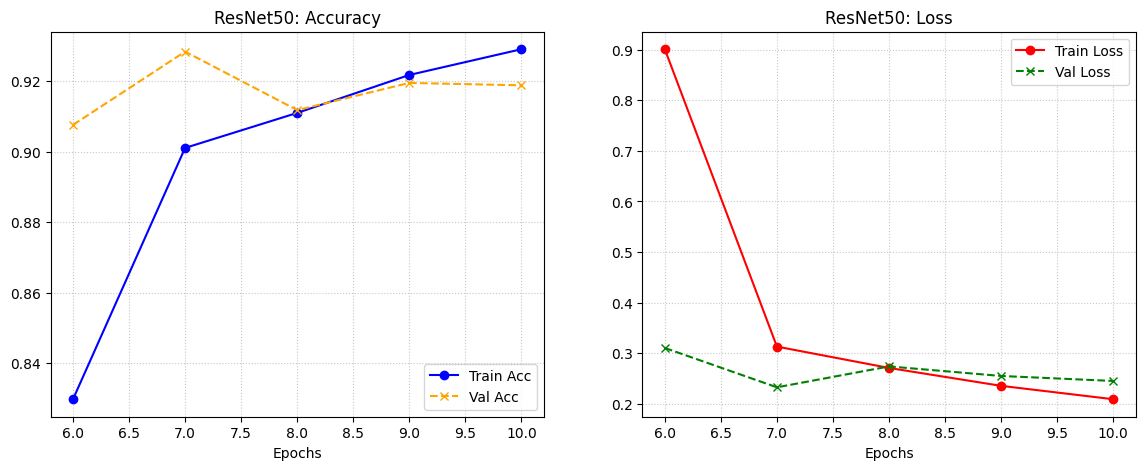

In [3]:
import matplotlib.pyplot as plt

def plot_phase2_history(history_obj, model_name, initial_epoch=5):
    plt.figure(figsize=(14, 5))
    
    # Calculate the dynamic epoch range for the X-axis
    epochs_trained = len(history_obj.history['accuracy'])
    epoch_range = range(initial_epoch + 1, initial_epoch + 1 + epochs_trained)
    
    plt.subplot(1, 2, 1)
    plt.plot(epoch_range, history_obj.history['accuracy'], label='Train Acc', color='blue', marker='o')
    plt.plot(epoch_range, history_obj.history['val_accuracy'], label='Val Acc', color='orange', linestyle='--', marker='x')
    plt.title(f'{model_name}: Accuracy')
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    plt.subplot(1, 2, 2)
    plt.plot(epoch_range, history_obj.history['loss'], label='Train Loss', color='red', marker='o')
    plt.plot(epoch_range, history_obj.history['val_loss'], label='Val Loss', color='green', linestyle='--', marker='x')
    plt.title(f'{model_name}: Loss')
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    plt.savefig(f'/kaggle/working/{model_name}_curves.png')
    plt.show()

if 'history' in locals(): 
    plot_phase2_history(history, 'ResNet50', INITIAL_EPOCH)